# Hartland Quay (Devon) — figure: the beds cut at the cliff

The fitted beds as nested surfaces, cut back along the hinge in equal steps from
the cliff face out over the wave-cut platform. Every isosurface saved by
`05d_hartland_quay_meshes` (LDI) or `05c_hartland_quay_surfe` (Surfe) is drawn.
Each cut edge is a fold profile at a known distance along the hinge. In front of
the cliff, anything above the platform is air and is not drawn.

`METHOD` chooses the fit: `"ldi"` for the paper figure, `"surfe"` for the
supplement, where interior extrema (closed bubbles) show as bright pink. Nothing
is fitted or meshed here; `curlew`, `torch` and `surfepy` are not needed. The
scene is rendered by Blender without a window (`exploded3d.build_cutaway`,
`render_exploded.py`); intermediate scenes go to `renders/`, only `figures/` is
final.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import exploded3d
import hartland_inputs
figstyle.apply()

METHOD = "ldi"                       # "ldi" (paper) or "surfe" (supplement)
MEMBER = 19                           # LDI ensemble member meshed by 05d (19 is the member in the paper)
TAG = METHOD if (METHOD != "ldi" or MEMBER == 0) else f"ldi_member_{MEMBER:02d}"   # names the meshes, renders and figure

RES_DIR = hartland_inputs.RESULTS_DIR
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RENDER_DIR = Path("renders") / f"{TAG}_terraces"

data = hartland_inputs.load_processed()
traces, cloud_xyz, hinge = data["traces"], data["cloud_xyz"], data["hinge"]
meshes = np.load(RES_DIR / f"meshes_{TAG}.npz")
print(f"{METHOD}: {len(meshes['isovalues'])} surfaces, {len(meshes['ext_points'])} interior extrema")


ldi: 12 surfaces, 0 interior extrema


## The cut

The cliff face is the photographed rock. In each `FACE_CELL` across the hinge and
in height, it is the most seaward cloud point above the platform, empty cells take
the nearest face, and it is smoothed over `FACE_SMOOTH` cells. Below the platform
and above the cliff it keeps that position.

The youngest surface is cut on that face. Each older one is cut the same distance
further seaward along the hinge, and the last step is the median seaward edge of
the platform. The step is printed, in metres, one line per surface. A surface is
kept on the cliff side of its own cut, and only in the rock: behind the cliff, or
below the platform. `MIN_AREA` drops a disconnected piece smaller than that.
`SMOOTH_ITER = 0` leaves the mesh as saved. The box is the cloud, so the figure is
the outcrop.


In [2]:
from scipy.ndimage import distance_transform_edt, gaussian_filter, map_coordinates

FACE_CELL = 5.0                            # m, cliff face measured in cells of this size
FACE_SMOOTH = 2.5                          # cells, smooth the face over about this many
SMOOTH_ITER = 0                            # Taubin passes per surface (0 = as meshed)
SMOOTH_BAND = 20                           # Taubin pass band: smaller irons out broader crumples
MIN_AREA = 300.0                           # m², drop a disconnected piece smaller than this

hinge = np.asarray(hinge, float)
hinge = hinge / np.linalg.norm(hinge)
hxy = np.array([hinge[0], hinge[1], 0.0])
hxy /= np.linalg.norm(hxy)                 # landward: the hinge points into the cliff
side = np.array([-hxy[1], hxy[0]])         # across the hinge, horizontal
z_beach = data["settings"]["z_beach"] - data["origin"][2]

cu = cloud_xyz[:, :2] @ side
ct = cloud_xyz @ hinge                     # metres along the hinge; larger is landward
cz = cloud_xyz[:, 2]
on_cliff = cz > z_beach
ua = np.floor(cu[on_cliff] / FACE_CELL).astype(int)
za = np.floor(cz[on_cliff] / FACE_CELL).astype(int)
umin, umax = int(ua.min()), int(ua.max())
zmin, zmax = int(za.min()), int(za.max())
face = np.full((zmax - zmin + 1, umax - umin + 1), np.inf)
np.minimum.at(face, (za - zmin, ua - umin), ct[on_cliff])   # most seaward rock in each cell
empty = ~np.isfinite(face)
face = face[tuple(distance_transform_edt(empty, return_distances=False, return_indices=True))]
face = gaussian_filter(face, sigma=FACE_SMOOTH, mode="nearest")

def face_at(across, z):
    """Metres along the hinge of the cliff face, at this position across it and this height."""
    iu = np.clip(np.asarray(across, float) / FACE_CELL - umin, 0, face.shape[1] - 1)
    iz = np.clip(np.asarray(z, float) / FACE_CELL - zmin, 0, face.shape[0] - 1)
    return map_coordinates(face, [iz, iu], order=1, mode="nearest")

sheets = exploded3d.sheets_from_saved(meshes, min_area=MIN_AREA, smooth_iter=SMOOTH_ITER, pass_band=SMOOTH_BAND)   # youngest first
# How far the platform reaches seaward of the cliff, per column across it.
plat = cz <= z_beach
cols = np.floor(cu[plat] / FACE_CELL).astype(int)
reach = []
for col in np.unique(cols):
    here = ct[plat][cols == col]
    at_face = float(face_at([(col + 0.5) * FACE_CELL], [z_beach])[0])
    if at_face - here.min() > FACE_CELL:
        reach.append(at_face - here.min())
STEP = float(np.median(reach) / max(len(sheets) - 1, 1))   # equal steps, cliff to the platform's edge
offsets = np.arange(len(sheets)) * STEP                    # youngest at the cliff, then seaward

def _keep(offset):
    def fn(p, offset=offset):
        p = np.atleast_2d(np.asarray(p, dtype=float))
        t = p @ hinge
        cliff = face_at(p[:, :2] @ side, p[:, 2])
        section = t - (cliff - offset)                              # >= 0 on the cliff side of this cut
        rock = np.maximum(t - cliff, z_beach - p[:, 2])             # >= 0 behind the cliff, or below the platform
        return np.minimum(section, rock)
    return fn

keep = [_keep(float(o)) for o in offsets]
pad = 5.0
BOX = np.vstack([cloud_xyz.min(0) - pad, cloud_xyz.max(0) + pad])   # the outcrop
print(f"platform {np.median(reach):.0f} m seaward of the cliff; step {STEP:.1f} m along the hinge")
for i, o in enumerate(offsets):
    print(f"  {i:2d}  {o:6.1f} m seaward" + ("  (the cliff)" if i == 0 else ""))
print(f"box {np.round(BOX[0])} to {np.round(BOX[1])}")


platform 122 m seaward of the cliff; step 11.1 m along the hinge
   0     0.0 m seaward  (the cliff)
   1    11.1 m seaward
   2    22.2 m seaward
   3    33.3 m seaward
   4    44.4 m seaward
   5    55.5 m seaward
   6    66.6 m seaward
   7    77.7 m seaward
   8    88.8 m seaward
   9    99.9 m seaward
  10   111.0 m seaward
  11   122.1 m seaward
box [-167. -240.  -25.] to [122. 183.  78.]


## Render

Surfaces in the colour ramp of the other figures, youngest dark blue to oldest
red; interior extrema bright pink (an enclosing shell where one closes, a sphere
otherwise). `OCCLUSION` darkens the gaps between nested sheets (screen-space ambient occlusion, with
soft sun shadows), `MATTE` takes off the plastic sheen, and `BACKFACE_DARKEN` shades the
underside of each sheet, so overturned limbs read as such. `SHEEN` brightens each sheet where it turns away from the view, so
closely stacked sheets separate; `RIM_LIGHT` adds a second sun from behind for the same effect
on the edges. `SLAB` draws each surface as a thin slab, like a card model, with its walls
in the darker shade of its colour; the rim tubes are then left out (`RIMS`). `WORLD_STRENGTH` and `SUN_ENERGY` set the light: lower surroundings
give deeper colours. `AZIMUTH` −90 looks from the sea along +x; less
negative swings the camera towards −y. −78 looks straight along the hinge (trend 78.7°), so the cliff
is seen face-on, and the steps recede along the hinge. The dark rims are the cut edges, one fold profile at each step.


In [3]:
AZIMUTH, ELEVATION = -78.0, 16.0           # degrees: along the hinge, into the cliff (face-on)
RESOLUTION = (2400, 1560)                  # px
ENGINE, SAMPLES = "EEVEE", 64
OCCLUSION = 10.0                           # m, ambient occlusion reach: the gaps between sheets darken (None = off)
MATTE = True                               # rough, low-sheen surfaces
BACKFACE_DARKEN = 0.3                      # undersides this much darker, so overturned limbs read
SHEEN = 0.0                                # brighter where a sheet turns away: stacked sheets separate (0 = off)
RIM_LIGHT = 0.                            # a second sun from behind, for the sheet edges (0 = off; try 1-2)
SLAB = 0.0                                 # m, draw each surface as a slab this thick, walls in a darker shade (0 = sheets)
SUBDIV = 1                                 # Catmull-Clark levels in the render only (0 = the mesh as saved)
RIMS = SLAB == 0                           # rim tubes along the cut edges (the slab walls replace them)
WORLD_STRENGTH, SUN_ENERGY = 0.35, 3.5
EXT_COLOR = "#FF1FA8"                      # interior extrema: bright pink, as in 02
GNOMON_LENGTH = 30.0                       # m

colors = [matplotlib.colors.to_hex(figstyle.ramp()(t)) for t in np.linspace(0.9, 0.1, len(sheets))]
extrema = [(p, exploded3d.shell_from_saved(meshes, e)) for e, p in enumerate(meshes["ext_points"])]
scene = exploded3d.build_cutaway(RENDER_DIR / "scene", surfaces=sheets, box=BOX, keep=keep, colors=colors,
                                 extrema=extrema, extremum_color=EXT_COLOR, min_area=MIN_AREA,
                                 ghost=None, occlusion=OCCLUSION, matte=MATTE,
                                 backface_darken=BACKFACE_DARKEN, sheen=SHEEN, rim_light=RIM_LIGHT,
                                 slab=SLAB, subdiv=SUBDIV, rims=RIMS,
                                 world_strength=WORLD_STRENGTH, sun_energy=SUN_ENERGY)
cam = exploded3d.fit_camera(tuple(zip(BOX[0], BOX[1])), AZIMUTH, ELEVATION, RESOLUTION)
render_png = exploded3d.render(scene, RENDER_DIR / "render.png", cam=cam, resolution=RESOLUTION,
                               engine=ENGINE, samples=SAMPLES)

gnomon_origin = np.asarray(cam["target"]) / 1e-3
gnomon_tips = exploded3d.build_gnomon(RENDER_DIR / "axes", origin=gnomon_origin, length=GNOMON_LENGTH,
                                      shaft_radius=0.9, head_radius=2.4, head_length=7.0)
gnomon_png = exploded3d.render(RENDER_DIR / "axes", RENDER_DIR / "axes.png", cam=cam, resolution=RESOLUTION,
                               engine=ENGINE, samples=SAMPLES)
# what 05f_hartland_quay_cut needs to compose this render with others from the same camera
import json
tolist = lambda o: np.asarray(o).tolist()
(RENDER_DIR / "camera.json").write_text(json.dumps(
    {"cam": cam, "resolution": list(RESOLUTION), "gnomon_origin": gnomon_origin, "gnomon_tips": gnomon_tips,
     "gnomon_length": GNOMON_LENGTH, "colors": colors, "n_extrema": int(len(meshes["ext_points"])),
     "box": BOX}, default=tolist, indent=1))
print("rendered", render_png)


rendered renders/ldi_member_19_terraces/render.png


## Figure

The render cropped to its contents, with the model axes to scale in a corner and
the colour key below.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote
  figures/fig05_hartland_quay_ldi_member_19.pdf
  figures/fig05_hartland_quay_ldi_member_19.png


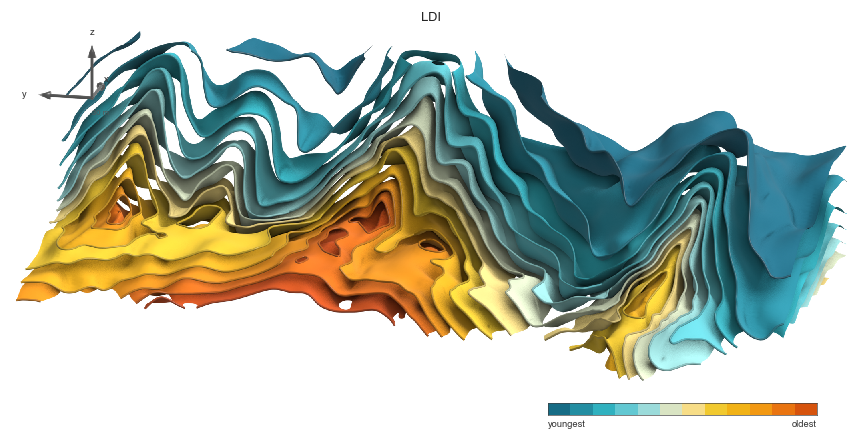

In [4]:
DPI = 300
img = np.asarray(Image.open(render_png).convert("RGBA"))
rows, cols = np.flatnonzero(img[..., 3].max(1) > 8), np.flatnonzero(img[..., 3].max(0) > 8)
pad = 10
r0, r1 = max(rows[0] - pad, 0), min(rows[-1] + pad + 1, img.shape[0])
c0, c1 = max(cols[0] - pad, 0), min(cols[-1] + pad + 1, img.shape[1])
crop = img[r0:r1, c0:c1]


def panel_pixels(arr, w_in, h_in):
    # Resample to the panel's size at DPI ourselves, on premultiplied alpha (no halo at the edges).
    size = (max(1, round(w_in * DPI)), max(1, round(h_in * DPI)))
    return np.asarray(Image.fromarray(arr).convert("RGBa").resize(size, Image.Resampling.LANCZOS).convert("RGBA"))


W = figstyle.PRINT_WIDTH
left, right, top, bottom = 0.05, 0.05, 0.30, 0.45
w_panel = W - left - right
h_panel = w_panel * (r1 - r0) / (c1 - c0)
H = top + h_panel + bottom
fig = figstyle.print_figure(height=H)
ax = fig.add_axes((left / W, bottom / H, w_panel / W, h_panel / H))
ax.imshow(panel_pixels(crop, w_panel, h_panel), interpolation="none")
ax.set_axis_off()
n_ext = len(meshes["ext_points"])
title = {"ldi": "LDI", "surfe": "SURFE"}[METHOD] + (f": {n_ext} interior extrema" if METHOD == "surfe" else "")
ax.set_title(title, color="0.15", fontproperties=figstyle._fp(size=11))

# the model axes, to scale, in the top-left corner
g = np.asarray(Image.open(gnomon_png).convert("RGBA"))
g_rows, g_cols = np.flatnonzero(g[..., 3].max(1) > 8), np.flatnonzero(g[..., 3].max(0) > 8)
gpad = 45
gr0, gr1 = g_rows[0] - gpad, g_rows[-1] + gpad + 1
gc0, gc1 = g_cols[0] - gpad, g_cols[-1] + gpad + 1
px_per_in = (c1 - c0) / w_panel
gw, gh = (gc1 - gc0) / px_per_in, (gr1 - gr0) / px_per_in
gax = fig.add_axes(((left + 0.01 * w_panel) / W, (bottom + h_panel - gh) / H, gw / W, gh / H), zorder=5)
gax.imshow(panel_pixels(g[gr0:gr1, gc0:gc1], gw, gh), interpolation="none", extent=(gc0, gc1, gr1, gr0))
pix = exploded3d.project(np.vstack([gnomon_origin, *gnomon_tips.values()]), cam, RESOLUTION)
for label, tip in zip("xyz", pix[1:]):
    at = tip + 0.25 * (tip - pix[0])
    gax.text(at[0], at[1], label, ha="center", va="center", fontproperties=figstyle._fp(size=8), color="0.2")
gax.text(pix[0][0], gr1 - 4, f"{GNOMON_LENGTH:.0f} m", ha="left", va="bottom",
         fontproperties=figstyle._fp(size=6.5), color="0.35")
gax.set_xlim(gc0, gc1); gax.set_ylim(gr1, gr0); gax.set_axis_off()

# colour key (youngest to oldest) and the marks
key = fig.add_axes(((left + 0.64 * w_panel) / W, 0.20 / H, 0.32 * w_panel / W, 0.10 / H))
key.imshow(np.array([matplotlib.colors.to_rgb(c) for c in colors])[None], aspect="auto")
key.set_xticks([]); key.set_yticks([])
for side in key.spines.values():
    side.set_linewidth(0.4)
key.text(0.0, -0.4, "youngest", transform=key.transAxes, ha="left", va="top", fontproperties=figstyle._fp(size=8), color="0.2")
key.text(1.0, -0.4, "oldest", transform=key.transAxes, ha="right", va="top", fontproperties=figstyle._fp(size=8), color="0.2")
handles = []
if n_ext:
    handles.append(Line2D([], [], ls="", marker="o", ms=5, mfc=EXT_COLOR, mec="white", mew=0.5,
                          label="interior extremum"))
if handles:
    fig.legend(handles=handles, loc="lower left", ncol=len(handles), frameon=False, bbox_to_anchor=(left / W, 0.12 / H))

written = figstyle.save(fig, FIG_DIR / f"fig05_hartland_quay_{TAG}")
print("wrote", *written, sep="\n  ")
plt.show()

## Data panel (for 05f)

The outcrop itself, for the top panel of the paper figure: the photogrammetric point cloud at
full density (`CLOUD_PLY`, about 10 million points), with the 45 traces the fits use as tubes
and the 167 bedding readings as slabs, as in the isocline figure (the way-up half in cyan, the
other half in red). It is rendered with the camera of the LDI render (`renders/ldi_terraces/camera.json`,
so run this section after `METHOD = "ldi"`), cropped to the same box, so the data sit exactly
where the model panels show the beds.

The cloud file is in the file frame with *z* pointing down: *z* is negated and the processed
`origin` subtracted, which puts it on the digitised data to within the point spacing (about
0.2 m). The points are drawn in exactly their photograph colours (self-lit, `unlit=True`), while the
tubes and slabs are lit; `SATURATION` and `LIGHTEN` tone the photograph down so they stand out,
and `exploded3d.shade_cloud` relights it by its own geometry (each point's normal from its
neighbours, lit from the upper left of the view), so the relief of the cliff reads. The traces and slabs are lifted `LIFT` m off the rock, towards the
camera, and cast shadows on the cloud from the same light (`exploded3d.cast_shadows`), so they read
as objects on the outcrop;
`POINT_RADIUS` is about the point spacing, so the cloud renders as a closed surface. The traces
are drawn at full density (the fits use 64 points of each). Written to `renders/data/`.

In [8]:
import json

CLOUD_PLY = Path("/Users/kamath92/Documents/Work/2026/Deformational Geological Modelling/Devon/HartlandQuay_Devon.ply")
POINT_RADIUS = 0.09                        # m, about the point spacing
SATURATION, LIGHTEN = 0.75, 0.08           # photo toned down: this much of its colour, mixed this far towards white
SHADE_AMBIENT, SHADE_DIFFUSE = 0.85, 0.20   # relief shading, light: colour x (ambient + diffuse * max(n.light, 0));
                                           # the photograph already carries its own shadows
TRACE_COLOR, TRACE_RADIUS = "#DD8452", 0.45   # m
LIFT = 1.0                                 # m, traces and slabs moved towards the camera, off the rock
SHADOW = 0.65                              # how far their cast shadows darken the cloud (0 = none)
BEDDING_SIZE = (8.0, 3.5, 1.0)             # m: each bedding reading, along strike, down dip and thick
BEDDING_COLORS = ("#2EC4D6", "#E0302A")    # its way-up half, and the other half (as the isocline)
DATA_DIR = Path("renders") / "data"

view = json.loads((Path("renders") / "ldi_terraces" / "camera.json").read_text())
data_cam, data_res, box = view["cam"], tuple(view["resolution"]), np.asarray(view["box"])

# the cloud, in the modelling frame
raw = CLOUD_PLY.open("rb").read(4096)
header = raw[:raw.index(b"end_header\n") + len(b"end_header\n")]
n_vertex = int(header.split(b"element vertex ")[1].split()[0])
ply = np.memmap(CLOUD_PLY, mode="r", offset=len(header), shape=(n_vertex,),
                dtype=np.dtype([("x", "<f4"), ("y", "<f4"), ("z", "<f4"), ("r", "u1"), ("g", "u1"), ("b", "u1")]))
xyz = np.c_[ply["x"], ply["y"], -ply["z"].astype(np.float64)] - data["origin"]
inside = np.all((xyz >= box[0]) & (xyz <= box[1]), axis=1)
xyz = xyz[inside]
rgb = np.c_[ply["r"], ply["g"], ply["b"]][inside] / 255.0
grey = rgb @ [0.299, 0.587, 0.114]
rgb = grey[:, None] + SATURATION * (rgb - grey[:, None])
rgb = rgb + LIGHTEN * (1.0 - rgb)
# relief shading from the points' own normals, lit from the upper left of the view
to_cam = np.subtract(data_cam["location"], data_cam["target"]); to_cam /= np.linalg.norm(to_cam)
light = 0.55 * to_cam - 0.6 * np.asarray(data_cam["right"]) + 0.6 * np.array([0.0, 0.0, 1.0])
rgb = exploded3d.shade_cloud(xyz, rgb, light=light, view=to_cam, ambient=SHADE_AMBIENT, diffuse=SHADE_DIFFUSE)
print(f"{len(xyz):,} of {n_vertex:,} points inside the box")

# the fitted traces at full density, and the bedding, lifted off the rock; their shadows on the cloud
full = dict(zip(data["all_trace_names"], data["all_traces"]))
fitted = [full[n] + LIFT * to_cam for n in data["trace_names"]]
gp = data["gp"] + LIFT * to_cam
casters = [(np.vstack([exploded3d.resample_polyline(t, 0.15) for t in fitted]), TRACE_RADIUS),
           (exploded3d.slab_samples(gp, data["gv"], BEDDING_SIZE, 0.3), 0.4)]
rgb = exploded3d.cast_shadows(xyz, rgb, casters, light=light / np.linalg.norm(light), strength=SHADOW)
scene = exploded3d.build_cloud(DATA_DIR / "scene", points=xyz, rgb=rgb, point_radius=POINT_RADIUS,
                               lines=fitted, line_color=TRACE_COLOR, line_radius=TRACE_RADIUS,
                               bedding=(gp, data["gv"]), bedding_size=BEDDING_SIZE,
                               bedding_colors=BEDDING_COLORS, unlit=True, sun_direction=light,
                               world_strength=0.9, sun_energy=1.5)
data_png = exploded3d.render(scene, DATA_DIR / "render.png", cam=data_cam, resolution=data_res,
                             engine="EEVEE", samples=64, timeout=3600)
(DATA_DIR / "camera.json").write_text(json.dumps({**view, "trace_color": TRACE_COLOR,
                                                  "bedding_colors": list(BEDDING_COLORS)}, indent=1))
print("rendered", data_png)

10,000,154 of 10,000,154 points inside the box
rendered renders/data/render.png


## Supplement: the spatial block hold-out

Each held-out block of `hartland_inputs.block_folds`, one row per block: the LDI fit of `05i` (left) and the Surfe
fit of `05c` (right), each fitted without that block, drawn on the point cloud seen along the hinge (y–z), as an image in discrete bands of its own scalar,
shaded by the relief of the outcrop. Dark grey: the traces the fold was fitted to; purple: the held-out traces;
pink circles: interior extrema. Each panel gives that fold's extrema, the median flatness of the held-out traces and the median
angle to the held-out bedding. Reads `results/blocks_ldi.npz` and `results/blocks_surfe.npz` only. Writes
`figures/supplement/figS_hartland_quay_blocks`.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


wrote
  figures/supplement/figS_hartland_quay_blocks.pdf
  figures/supplement/figS_hartland_quay_blocks.png


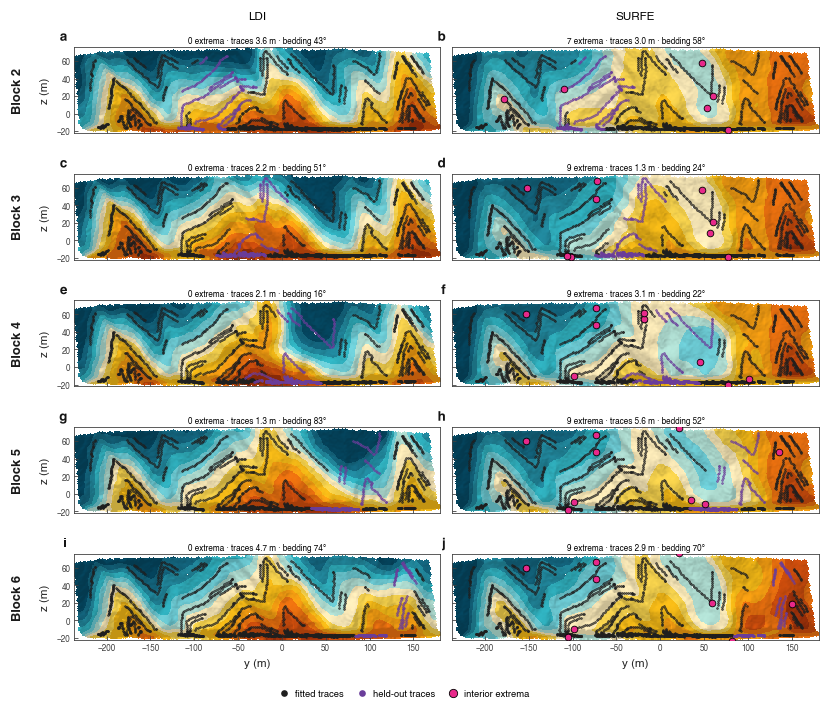

In [17]:
import diagnostics
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm, ListedColormap
from scipy.ndimage import distance_transform_edt, gaussian_filter

N_BANDS = 12                                # bands of each fold's scalar, between its oldest and youngest fitted trace
PIXEL = 1.                                  # m, image cell along the cliff and in height
FILL = 3.0                                  # m, gaps in the cloud up to this are filled; beyond, blank
RELIEF_SMOOTH = 1.                         # m, smoothing of the cliff before shading (smaller is sharper)
FIELD_SMOOTH = 2.0                          # m, smoothing of the scalar between cloud points
EXTREMA_COLOR = "#E7298A"                   # interior extrema, as in the main-text figures
HELD_COLOR = "#6A3D9A"                      # held-out traces: purple, off the colour ramp

blk = {m: np.load(RES_DIR / f"blocks_{m}.npz") for m in ("ldi", "surfe")}
every = int(blk["ldi"]["cloud_every"])
assert every == int(blk["surfe"]["cloud_every"])
cloud = data["cloud_xyz"][::every]
folds = hartland_inputs.block_folds(data["traces"], data["gp_fit"], data["u_ax"])
traces = data["traces"]

# The cloud as an image seen along the hinge (y across, z up): each pixel keeps the point nearest the viewer (lowest x),
# empty pixels take their nearest filled neighbour within FILL, and the rest is blank.
y0, z0 = cloud[:, 1].min() - 2, cloud[:, 2].min() - 2
ny = int((cloud[:, 1].max() + 2 - y0) / PIXEL) + 1
nz = int((cloud[:, 2].max() + 2 - z0) / PIXEL) + 1
iy = ((cloud[:, 1] - y0) / PIXEL).astype(int)
iz = ((cloud[:, 2] - z0) / PIXEL).astype(int)
pix = iz * ny + iy
front = np.full(nz * ny, -1)
by_depth = np.argsort(-cloud[:, 0])          # far first, so the nearest point is written last
front[pix[by_depth]] = by_depth
front = front.reshape(nz, ny)
dist, near = distance_transform_edt(front < 0, return_indices=True)
index = front[near[0], near[1]]
inside = dist * PIXEL <= FILL
extent = (y0, y0 + ny * PIXEL, z0, z0 + nz * PIXEL)

depth = gaussian_filter(cloud[index, 0], RELIEF_SMOOTH / PIXEL)   # hillshade of the cliff, lit from the upper left
d_dz, d_dy = np.gradient(depth, PIXEL)
light_dir = np.array([-0.4, 0.5, 1.0]) / np.linalg.norm([-0.4, 0.5, 1.0])
lambert = (-d_dy * light_dir[0] - d_dz * light_dir[1] + light_dir[2]) / np.sqrt(d_dy ** 2 + d_dz ** 2 + 1.0)
SHADE_STRENGTH = 0.35                       # 0: flat colours; 1: full hillshade
shade = 1.0 + SHADE_STRENGTH * (np.clip(0.35 + 0.8 * lambert, 0.45, 1.2) - 1.0)

left, right, gap, row_gap, top, bottom = 0.80, 0.08, 0.10, 0.34, 0.32, 0.55
pw = (figstyle.PRINT_WIDTH - left - right - gap) / 2
ph = pw * (extent[3] - extent[2]) / (extent[1] - extent[0])
n = len(folds)
fig_h = top + n * ph + (n - 1) * row_gap + bottom
fig = figstyle.print_figure(height=fig_h)
fw = figstyle.PRINT_WIDTH

for r, f in enumerate(folds):
    b = f["block"]
    for col, (m, name) in enumerate((("ldi", "LDI"), ("surfe", "SURFE"))):
        R = blk[m]
        assert np.array_equal(R[f"test_{b}"], f["test"]), "the saved folds differ from block_folds"
        ax = fig.add_axes([(left + col * (pw + gap)) / fw, (bottom + (n - 1 - r) * (ph + row_gap)) / fig_h, pw / fw, ph / fig_h])
        edges = np.sort(diagnostics.evenly_spaced_levels(R[f"levels_{b}"], N_BANDS))
        cmap = ListedColormap(figstyle.ramp()(np.linspace(0.0, 1.0, len(edges) + 1)))
        norm = BoundaryNorm(edges, cmap.N, extend="both")
        phi = gaussian_filter(R[f"phi_{b}"][index].astype(float), FIELD_SMOOTH / PIXEL)   # smooth between cloud points
        rgba = np.array(cmap(norm(phi)), dtype=float)
        rgba[..., :3] = np.clip(rgba[..., :3] * shade[..., None], 0.0, 1.0)
        rgba[..., 3] = inside
        ax.imshow(rgba, origin="lower", extent=extent, interpolation="nearest", rasterized=True, zorder=1)
        for t in f["train"]:
            ax.plot(t[:, 1], t[:, 2], ".", ms=0.9, color="0.12", zorder=3)
        for k in f["test"]:
            ax.plot(traces[k][:, 1], traces[k][:, 2], ".", ms=0.9, color=HELD_COLOR, zorder=4)
        ext = R[f"ext_xyz_{b}"]
        if len(ext):
            ax.scatter(ext[:, 1], ext[:, 2], s=16, facecolors=EXTREMA_COLOR, edgecolors="k", linewidths=0.5, zorder=5)
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        ax.set_aspect("equal")
        ax.tick_params(labelsize=figstyle.pt(7), direction="in")
        ax.text(0.5, 1.02, f"{int(R[f'extrema_{b}'])} extrema · traces {np.median(R[f'flat_{b}']):.1f} m · "
                           f"bedding {np.median(R[f'ang_{b}']):.0f}°",
                transform=ax.transAxes, fontsize=figstyle.pt(7), ha="center", va="bottom")
        if r == 0:
            ax.text(0.5, 1.30, name, transform=ax.transAxes, ha="center", va="bottom", fontsize=figstyle.pt(10))
        if r < n - 1:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel("y (m)")
        if col == 0:
            ax.set_ylabel("z (m)")
            figstyle.row_label(ax, f"Block {b + 1}")
        else:
            ax.set_yticklabels([])
        figstyle.panel_label(ax, "abcdefghijklmnopqrstuvwxyz"[2 * r + col])

handles = [Line2D([], [], ls="none", marker="o", ms=3, color="0.12", label="fitted traces"),
           Line2D([], [], ls="none", marker="o", ms=3, color=HELD_COLOR, label="held-out traces"),
           Line2D([], [], ls="none", marker="o", ms=5, mfc=EXTREMA_COLOR, mec="k", mew=0.5, label="interior extrema")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0),
           fontsize=figstyle.pt(8))
(FIG_DIR / "supplement").mkdir(parents=True, exist_ok=True)
written = figstyle.save(fig, FIG_DIR / "supplement" / "figS_hartland_quay_blocks")
print("wrote", *written, sep="\n  ")
plt.show()